In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git transformers
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

  Preparing metadata (setup.py) ... done


In [2]:
import os, re, cv2, torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline
from segment_anything import sam_model_registry, SamPredictor

os.makedirs("input", exist_ok=True)
os.makedirs("images/overlay", exist_ok=True)
os.makedirs("images/cutout", exist_ok=True)

In [3]:
from google.colab import files
import shutil
uploaded = files.upload()
for f in uploaded:
    shutil.move(f, f"input/{f}")
print(sorted(os.listdir("input")))

Saving dress.jpeg to dress.jpeg
Saving T_shirt.jpeg to T_shirt.jpeg
Saving pants.jpeg to pants.jpeg
['T_shirt.jpeg', 'dress.jpeg', 'pants.jpeg']


In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth").to(device)
predictor = SamPredictor(sam)

detector = pipeline("zero-shot-object-detection",
                    model="google/owlvit-base-patch32",
                    device=0 if device == "cuda" else -1)

Device: cpu


config.json:   0%|          | 0.00/4.42k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  613MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

In [16]:
def segment(path, label):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    dets = detector(Image.fromarray(img),
                    candidate_labels=[label, f"a photo of a {label}"],
                    threshold=0.01)
    print(path, "->", len(dets), "detections")
    if not dets:
        return None
    d = max(dets, key=lambda x: x["score"])
    b = d["box"]
    box = np.array([b["xmin"], b["ymin"], b["xmax"], b["ymax"]])

    predictor.set_image(img)
    masks, scores, _ = predictor.predict(box=box, multimask_output=True)
    i = int(np.argmax(scores))
    return img, box, d["score"], masks[i], float(scores[i])

In [17]:

if os.path.exists("input/T_shirt.jpeg"):
    os.rename("input/T_shirt.jpeg", "input/shirt.jpeg")

results, rows = [], []
for f in sorted(os.listdir("input")):
    name = os.path.splitext(f)[0]
    label = re.sub(r"[\d_\-\s]+$", "", name).replace("_", " ")
    out = segment(f"input/{f}", label)
    if out is None:
        print("No detection:", f)
        continue
    img, box, det_score, mask, sam_score = out

    ov = img.copy()
    ov[mask] = (0.5 * ov[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(ov, (x1, y1), (x2, y2), (0, 255, 0), 2)
    Image.fromarray(ov).save(f"images/overlay/{name}.png")

    rgba = np.dstack([img, (mask * 255).astype(np.uint8)])
    Image.fromarray(rgba).save(f"images/cutout/{name}.png")

    results.append((name, img, ov, rgba))
    rows.append({"image": f, "prompt": label,
                 "detector_score": round(det_score, 3),
                 "sam_score": round(sam_score, 3),
                 "mask_area_%": round(mask.mean() * 100, 1)})

df = pd.DataFrame(rows)
df.to_csv("images/results_table.csv", index=False)
df

input/dress.jpeg -> 16 detections
input/pants.jpeg -> 14 detections
input/shirt.jpeg -> 7 detections


,image,prompt,detector_score,sam_score,mask_area_%
0,dress.jpeg,dress,0.628,0.995,22.1
1,pants.jpeg,pants,0.291,0.998,18.0
2,shirt.jpeg,shirt,0.084,0.971,38.9


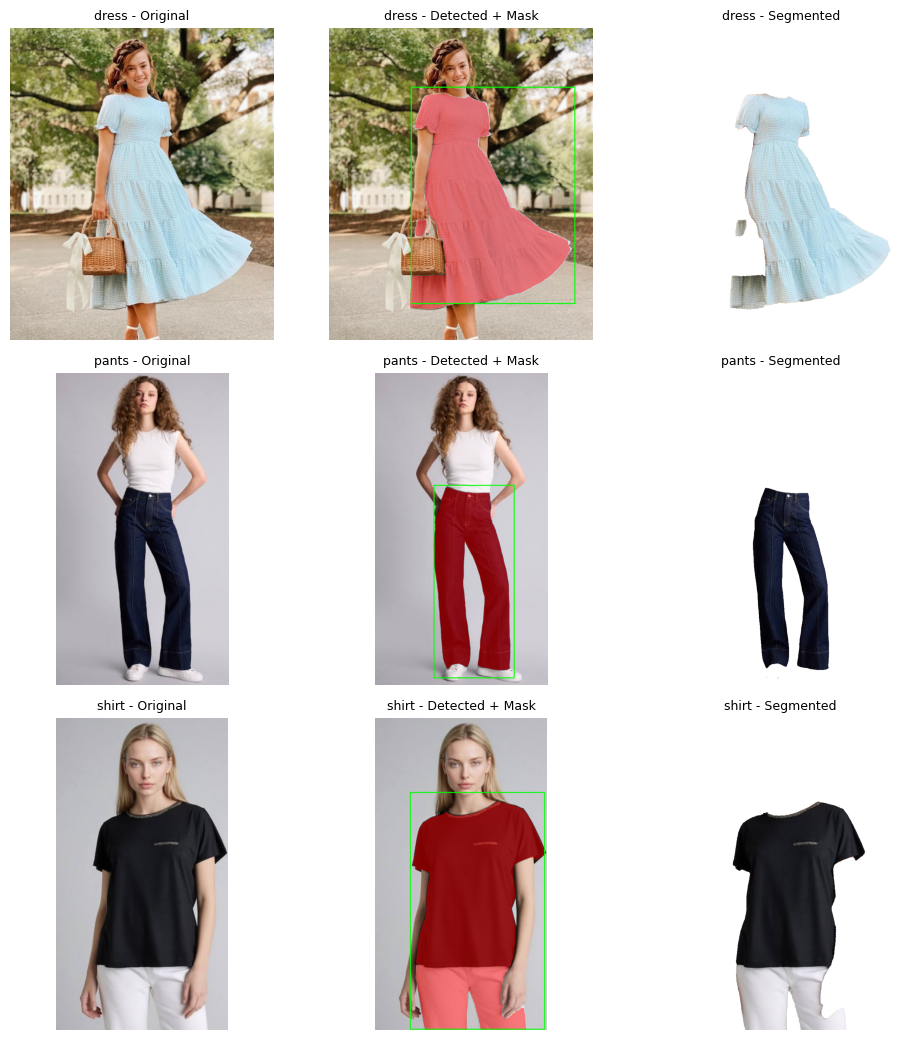

In [18]:
n = len(results)
fig, axes = plt.subplots(n, 3, figsize=(10, 3.5 * n), squeeze=False)
for r, (name, img, ov, rgba) in enumerate(results):
    for c, (im, t) in enumerate([(img, "Original"), (ov, "Detected + Mask"), (rgba, "Segmented")]):
        axes[r][c].imshow(im); axes[r][c].axis("off")
        axes[r][c].set_title(f"{name} - {t}", fontsize=9)
plt.tight_layout()
plt.savefig("images/results_grid.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
!zip -r project_outputs.zip images
from google.colab import files
files.download("project_outputs.zip")

  adding: images/ (stored 0%)
  adding: images/cutout/ (stored 0%)
  adding: images/cutout/pants.png (deflated 0%)
  adding: images/cutout/shirt.png (deflated 0%)
  adding: images/cutout/dress.png (deflated 0%)
  adding: images/results_grid.png (deflated 1%)
  adding: images/overlay/ (stored 0%)
  adding: images/overlay/pants.png (deflated 0%)
  adding: images/overlay/shirt.png (deflated 0%)
  adding: images/overlay/dress.png (deflated 0%)
  adding: images/results_table.csv (deflated 28%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>